# Mandatory assignment 3

**GitHub repository:** https://github.com/Sanitysr163216/TECH2-H26-assignment3.git

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

### Part 1.1

In [1]:
import pandas as pd

file = "SCF_10pct.csv"
df = pd.read_csv(file)
df

,id,year,age,educ,stocks,equity
0,0,1989,35,2.0,0.0,0.0
1,1,1989,33,2.0,0.0,0.0
2,2,1989,62,1.0,0.0,0.0
3,3,1989,23,2.0,0.0,0.0
4,4,1989,70,1.0,0.0,0.0
...,...,...,...,...,...,...
5803,5803,2022,21,2.0,0.0,0.0
5804,5804,2022,33,3.0,0.0,0.0
5805,5805,2022,81,2.0,100000.0,100000.0
5806,5806,2022,58,3.0,40000.0,1212000.0


In [2]:
print(f"The columns and their non-missing values are: \n{df.count()}")

The columns and their non-missing values are: 
id        5808
year      5808
age       5808
educ      5792
stocks    5790
equity    5792
dtype: int64


### Part 1.2

In [3]:
# One step drop
# df_dropna = df.dropna()
# print(f"Observations dropped: \n{df.count() - df_dropna.count()} \n")
# print(f"Remaining observations: \n{df_dropna.count()}")

In [4]:
# Observations are dropped sequentially, so each count excludes rows already dropped for earlier variables.

df_dropna = df
for year in df.columns:
    n_before = len(df_dropna)
    mask = df_dropna[year].notna()
    df_dropna = df_dropna[mask]
    n_after = len(df_dropna)

    print(f"Dropped {n_before - n_after} rows in the column {year}")
    print(f"There remain {n_after} rows")


Dropped 0 rows in the column id
There remain 5808 rows
Dropped 0 rows in the column year
There remain 5808 rows
Dropped 0 rows in the column age
There remain 5808 rows
Dropped 16 rows in the column educ
There remain 5792 rows
Dropped 18 rows in the column stocks
There remain 5774 rows
Dropped 16 rows in the column equity
There remain 5758 rows


### Part 1.3

In [5]:
mask_age = (df_dropna["age"] >= 25) & (df_dropna["age"] <= 89)
df_final = df_dropna[mask_age]

print(f"Observations dropped: \n{len(df_dropna) - len(df_final)}\n")
print(f"Remaining observations: \n{len(df_final)}")

Observations dropped: 
326

Remaining observations: 
5432


### Part 1.4

In [6]:
direct = df_final["stocks"] > 0
df_final["direct"] = direct.astype(int)

overall = df_final["equity"] > 0
df_final["overall"] = overall.astype(int)

df_final

,id,year,age,educ,stocks,equity,direct,overall
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0
5,5,1989,50,1.0,0.0,0.0,0,0
...,...,...,...,...,...,...,...,...
5802,5802,2022,77,3.0,0.0,0.0,0,0
5804,5804,2022,33,3.0,0.0,0.0,0,0
5805,5805,2022,81,2.0,100000.0,100000.0,1,1
5806,5806,2022,58,3.0,40000.0,1212000.0,1,1


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

### Part 2.1

In [7]:
def participation_rate(indicator):
    """Participation rate function

    Parameters
    ----------
    indicator : one-dimensional sequence
        0/1 values

    Returns
    -------
    float
        percentage
    """
    count = 0
    total = 0
    for i in indicator:
        total += 1
        if i == 1:
            count += 1
    pct = count / total * 100
    return pct

### Part 2.2

In [8]:
pct_direct = round(participation_rate(df_final['direct']), 2)
pct_overall = round(participation_rate(df_final['overall']), 2)

print(f'The direct participation rate is {pct_direct}%. \nThe overall participation rate is {pct_overall}%.')

The direct participation rate is 16.96%. 
The overall participation rate is 49.41%.


### Part 2.3

In [9]:
pct_direct_mean = round(df_final['direct'].mean() * 100, 2)
pct_overall_mean = round(df_final['overall'].mean() * 100, 2)

print(f'The direct participation rate is {pct_direct_mean}%. \nThe overall participation rate is {pct_overall_mean}%.')

The direct participation rate is 16.96%. 
The overall participation rate is 49.41%.


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

### Part 3.1 and Part 3.2

In [10]:
direct = []
overall = []

for educ in sorted(df_final['educ'].unique()):
    iseduc = educ == df_final['educ']
    df_educ = df_final[iseduc]

    pct_direct_educ = participation_rate(df_educ['direct'])
    pct_overall_educ = participation_rate(df_educ['overall'])

    direct.append(pct_direct_educ)
    overall.append(pct_overall_educ)

    print(f'The direct participation rate of education category {educ} is: {round(pct_direct_educ, 1)}%')
    print(f'The overall participation rate of education category {educ} is: {round(pct_overall_educ, 1)}%\n')


The direct participation rate of education category 1.0 is: 4.4%
The overall participation rate of education category 1.0 is: 17.3%

The direct participation rate of education category 2.0 is: 11.4%
The overall participation rate of education category 2.0 is: 39.9%

The direct participation rate of education category 3.0 is: 13.5%
The overall participation rate of education category 3.0 is: 48.3%

The direct participation rate of education category 4.0 is: 30.5%
The overall participation rate of education category 4.0 is: 73.5%



In [11]:
# Groupby method
# df_educ = df_final.groupby('educ')
# pct_direct_educ = df_educ['direct'].mean() * 100
# pct_overall_educ = df_educ['overall'].mean() * 100

### Part 3.3

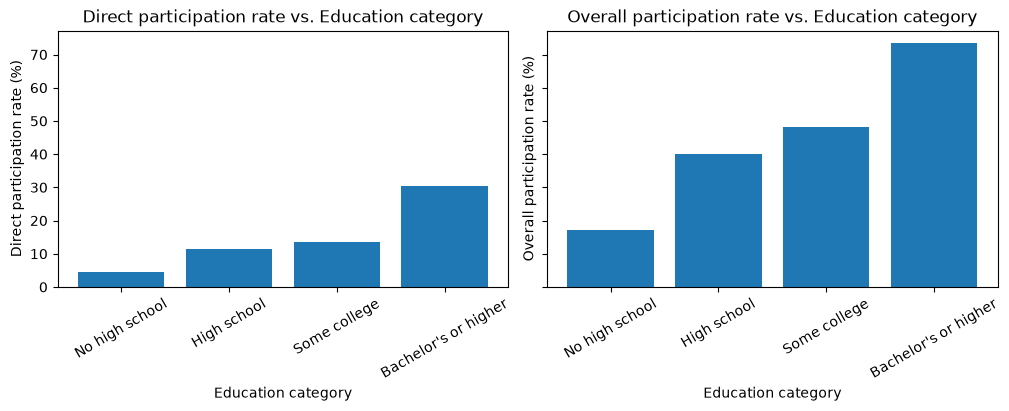

In [12]:
import matplotlib.pyplot as plt

educ_level = [1, 2, 3, 4]
educ_labels = ['No high school', 'High school', 'Some college', "Bachelor's or higher"]

fig, axes = plt.subplots(1, 2, layout='constrained', figsize=(10, 4), sharey=True)
axes[0].bar(educ_level, direct)
axes[1].bar(educ_level, overall)

axes[0].set_title('Direct participation rate vs. Education category')
axes[0].set_xlabel('Education category')
axes[0].set_ylabel('Direct participation rate (%)')
axes[0].set_xticks(educ_level, educ_labels, rotation=30)

axes[1].set_title('Overall participation rate vs. Education category')
axes[1].set_xlabel('Education category')
axes[1].set_ylabel('Overall participation rate (%)')
axes[1].set_xticks(educ_level, educ_labels, rotation=30)

plt.show()

People with a bachelor's degree or higher education have the highest participation rate in the stock market. As education level increases, there is an increase in the participation rate. The largest gap appears between 'Some college' and 'Bachelor's or higher'.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

### Part 4.1

In [13]:
years = df_final['year'].unique()
years_dr_part = {}
years_oa_part = {}
for year in years:
    df_year = df_final[df_final['year'] == year]
    year_direct_part = participation_rate(df_year['direct'])
    year_overall_part = participation_rate(df_year['overall'])

    years_dr_part[year] = year_direct_part
    years_oa_part[year] = year_overall_part

    print(f'{year}: direct: {year_direct_part:.1f}%\n'
          f'      overall: {year_overall_part:.1f}%')

1989: direct: 15.6%
      overall: 31.6%
1992: direct: 18.3%
      overall: 40.1%
1995: direct: 15.7%
      overall: 45.9%
1998: direct: 19.9%
      overall: 51.2%
2001: direct: 21.8%
      overall: 57.0%
2004: direct: 18.9%
      overall: 54.7%
2007: direct: 17.3%
      overall: 56.5%
2010: direct: 17.4%
      overall: 50.3%
2013: direct: 14.8%
      overall: 49.9%
2016: direct: 12.3%
      overall: 52.0%
2019: direct: 12.4%
      overall: 49.8%
2022: direct: 19.2%
      overall: 54.3%


### Part 4.2

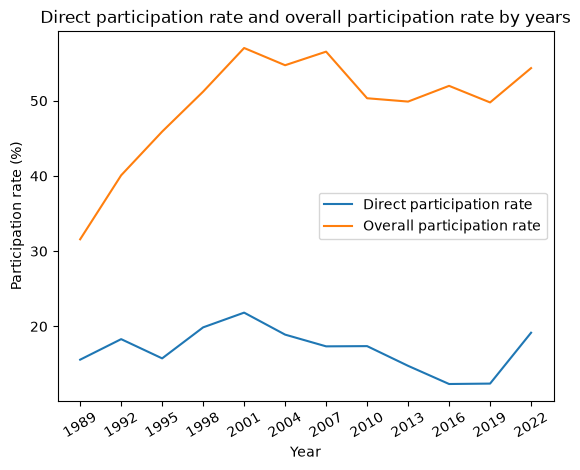

In [14]:
plt.plot(years, years_dr_part.values(), label='Direct participation rate')
plt.plot(years, years_oa_part.values(), label='Overall participation rate')

plt.title('Direct participation rate and overall participation rate by years')
plt.xlabel('Year')
plt.ylabel('Participation rate (%)')
plt.xticks(years, rotation=30)
plt.legend()

plt.show()

### Part 4.3

In [15]:
# All changes
# df_rates = pd.DataFrame({'Direct participation rate': years_dr_part.values(),
#                          'Overall participation rate': years_oa_part.values()},
#                          index=years)
# df_pct = df_rates.pct_change() * 100
# df_rates[['% change in direct participation rate', '% change in overall participation rate']] = df_pct
# df_rates

In [16]:
print(f'1989 to 2022: Direct: {years_dr_part[2022] - years_dr_part[1989]:.1f} percentage points')
print(f'              Overall: {years_oa_part[2022] - years_oa_part[1989]:.1f} percentage points')

1989 to 2022: Direct: 3.6 percentage points
              Overall: 22.8 percentage points


### Part 4.4

There have been many fluctuations in the direct participation rate from 1989 to 2022. The overall participation rate kept increasing from 1989 to 2001, then fluctuated around 50% to 57% from 2001 to 2022. While the overall participation rate increased from 1989 to 2001, the direct participation rate increased only slightly, which means that the increase in overall participation rate was mainly driven by a rise in indirect participation in the stock market.

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.